# General Data Science Track — Session 05
## From exploratory plots to a defensible linear model
**MED-EL research preparation · Estimated core time: 60 minutes**

## Why this matters
Research question: **“At baseline, how is the mean diagonal telemetry proxy associated with patient age and fictional array type?”** Refresh the Python equivalent of an R `lm()` workflow: plot first, define the analysis sample, fit a modest model, inspect residuals and influence, and interpret a coefficient with uncertainty. This is association analysis on synthetic data.

## Learning objectives
- Build an explicit baseline analysis sample with one row per patient.
- Fit formula-based OLS models with categorical predictors in statsmodels.
- Extract coefficients, confidence intervals, fitted values, and residuals.
- Inspect model form, unequal variance, and influential observations.
- Separate adjusted associations from causal or predictive claims.

## R-to-Python bridge
| R | Python |
|---|---|
| `lm(y ~ x + factor(g), data=d)` | `smf.ols("y ~ x + C(g)", data=d).fit()` |
| `summary(fit)` | `fit.summary()` |
| `coef(fit)`, `confint(fit)` | `fit.params`, `fit.conf_int()` |
| `fitted(fit)`, `residuals(fit)` | `fit.fittedvalues`, `fit.resid` |
| `predict(..., interval="confidence")` | `fit.get_prediction(new_data).summary_frame()` |

Import `statsmodels.formula.api as smf`. A model specification and a fitted result are different objects: `.fit()` creates the result. `C(...)` in a formula requests categorical coding.

## Suggested pacing
Tasks 1–3: 18 min · Tasks 4–6: 21 min · Tasks 7–8: 13 min · Retrieval/reasoning/reflection: 8 min.

## Inputs and analysis contract
Start Jupyter from the repository root and select **Python (learning-python)** (`.venv`). All files already exist in `data/ci_telemetry/`; no downloads or prior notebook variables are needed. Read [the data dictionary](data/ci_telemetry/README.md) when a field is unfamiliar.

**All data are synthetic.** There are 96 patients with exactly one implant each, 360 observed visits, and 144 directed cell records per visit. Matrix rows stimulate; columns record. Contacts 1–12 have an index order but no claimed anatomical direction. These are teaching conventions, not a description of MED-EL's internal export. `voltage_mv / stim_current_ua` gives a synthetic V/I proxy in kΩ; it is not automatically the manufacturer's clinical impedance measurement. Preserve the original tables. Write short explanations in new markdown cells or print them. Exercise cells are intentionally empty.

Load `visit_features.csv` (360×18), whose observed feature definitions are in the data dictionary. Use baseline (`visit_month == 0`) only. Outcome: `diag_mean_kohm`. Predictors: centered age, `array_type`, and `protocol`. Use an explicit complete-case sample for these variables, retaining a count of excluded patients. Do not use all visits as independent rows. No previous notebook output is required.

## Task 1 — Define the estimand and sample (6 min)
Load the feature table into `features`. Select baseline into `baseline`. Predict its row count before running; confirm 96 unique patients. Report missingness for the outcome and candidate predictors.

Create `model_data` using complete cases of `diag_mean_kohm`, `age_at_implant_years`, `array_type`, and `protocol`. Expect 90 patients, with no duplicate IDs. Create `age_centered = age_at_implant_years - 50`.

Methods: `.loc[...]`, `.copy()`, `.isna().sum()`, `.dropna(subset=[...])`. Explain whose association you estimate after excluding six missing ages. Use this exact same sample for both models below.

In [92]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import statsmodels.api as sm
import matplotlib.pyplot as plt
from plotnine import *  

In [43]:
features = pd.read_csv("data/ci_telemetry/visit_features.csv")
features.head()
baseline = features.loc[features["visit_month"] == 0]
baseline.head()

baseline["age_centered"] = baseline["age_at_implant_years"] - 50


In [44]:
# Create model data
model_data = baseline[["patient_id", "diag_mean_kohm", "age_at_implant_years", "array_type", "protocol"]]
model_data = model_data.dropna()
model_data["age_centered"] = model_data["age_at_implant_years"] - 50
model_data["patient_id"].unique().shape

(90,)

## Task 2 — Explore the variables before fitting (6 min)
With plotnine, draw baseline diagonal mean against age, color by array type, and facet by protocol. Add points first; optionally add an unadjusted straight trend per array with `geom_smooth(method="lm", se=False)`.

Also display a table of counts by array and protocol. Report the observed age range. Does a straight age association look like a useful starting approximation? Do not present the plot's within-facet trends as the adjusted model result.

Methods: `geom_point`, `facet_wrap("~protocol")`, `pd.crosstab(...)`, `.min()`, `.max()`.

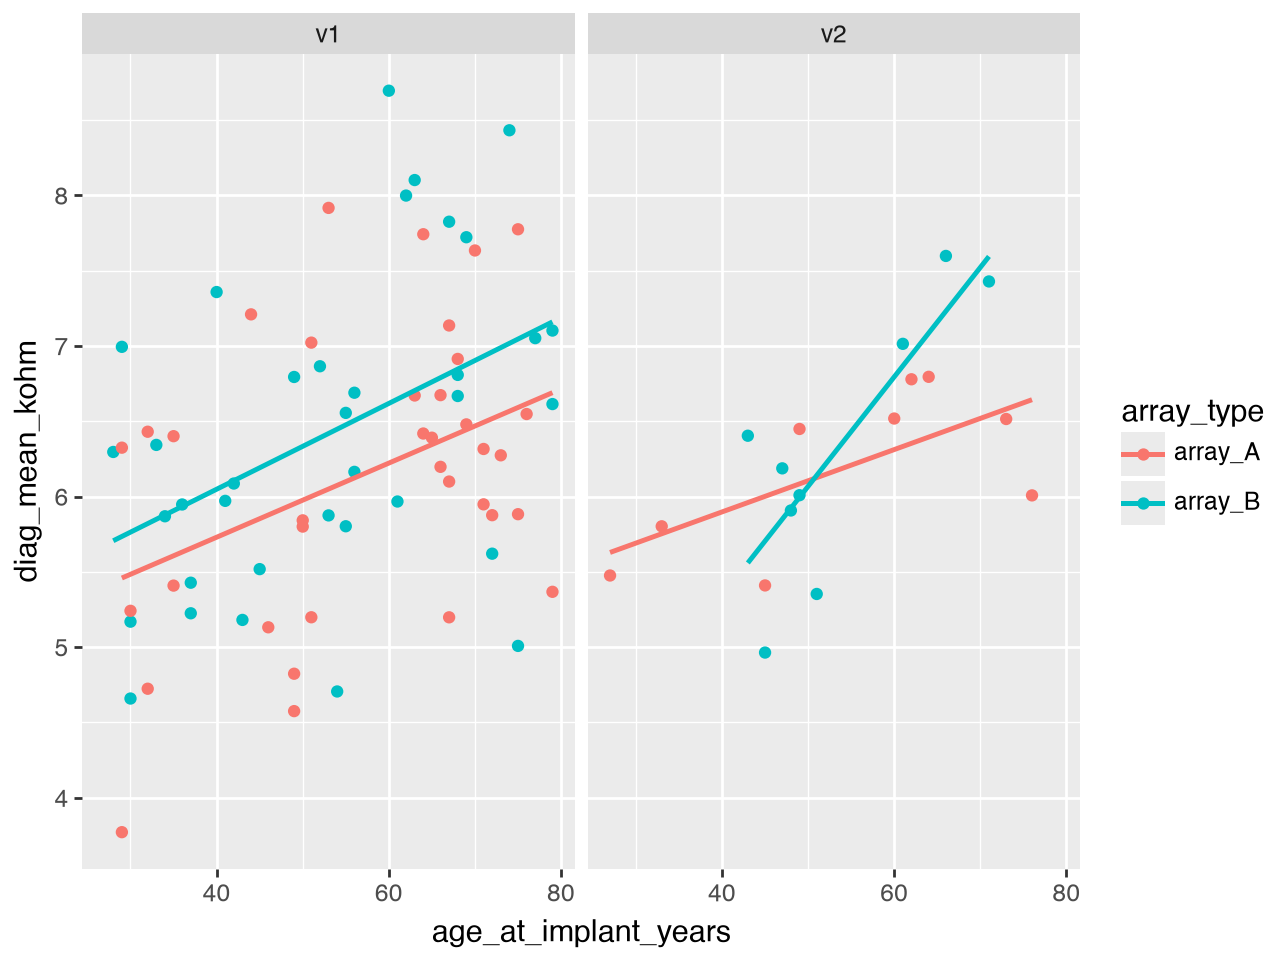

In [48]:
(
    ggplot(model_data, aes(x = "age_at_implant_years", y = "diag_mean_kohm", color = "array_type") ) + 
    geom_point() +
    geom_smooth(method = "lm", se = False) +
    facet_wrap("~protocol")
)

In [47]:
table_counts = model_data.groupby(["array_type", "protocol"]).agg(
    counts=("patient_id", "size")
).reset_index()
table_counts

,array_type,protocol,counts
0,array_A,v1,36
1,array_A,v2,9
2,array_B,v1,36
3,array_B,v2,9


Yes, an age association looks useful. much less people on the v2 protocol. bu in general, the higher the age, the higher the diag_kohm. This remains to be proven.

## Task 3 — Fit a baseline and adjusted OLS model (6 min)
Fit `simple` with diagonal mean as outcome and centered age as the only predictor. Fit `adjusted` with centered age plus categorical array type and protocol. Use `missing="raise"` to avoid silently changing the sample. Inspect both summaries and verify `nobs == len(model_data)`.

Unrelated formula example:
```python
fit = smf.ols("plant_height ~ rainfall + C(soil)", data=garden, missing="raise").fit()
```
Identify the categorical reference levels from the parameter names and data. Explain the intercept at age 50 in the reference array/protocol. Comparing R² here is descriptive, not an out-of-sample evaluation.

In [52]:
simple = smf.ols("diag_mean_kohm ~ age_centered",
                data=model_data,
                missing='raise').fit()
adjusted = smf.ols("diag_mean_kohm ~ age_centered + array_type + protocol", 
                   data=model_data,
                   missing='raise').fit()

In [54]:
simple.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         diag_mean_kohm   R-squared:                       0.181
Model:                            OLS   Adj. R-squared:                  0.172
Method:                 Least Squares   F-statistic:                     19.47
Date:                Sun, 27 Sep 2026   Prob (F-statistic):           2.88e-05
Time:                        11:25:16   Log-Likelihood:                -113.50
No. Observations:                  90   AIC:                             231.0
Df Residuals:                      88   BIC:                             236.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        6.1520      0.095     64.451      0.000       5.962       6.342
age_centered     0.0264      0.006      4.413      0.000       0.014       0.038
==============================================================================
Omnibus:                        0.486   Durbin-Watson:                   1.838
Prob(Omnibus):                  0.784   Jarque-Bera (JB):                0.600
Skew:                           0.160   Prob(JB):                        0.741
Kurtosis:                       2.759   Cond. No.                         16.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [55]:
adjusted.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         diag_mean_kohm   R-squared:                       0.212
Model:                            OLS   Adj. R-squared:                  0.185
Method:                 Least Squares   F-statistic:                     7.723
Date:                Sun, 27 Sep 2026   Prob (F-statistic):           0.000126
Time:                        11:25:30   Log-Likelihood:                -111.76
No. Observations:                  90   AIC:                             231.5
Df Residuals:                      86   BIC:                             241.5
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
=========================================================================================
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 5.9782      0.141     42.308      0.000       5.697       6.259
array_type[T.array_B]     0.3346      0.182      1.841      0.069      -0.027       0.696
protocol[T.v2]            0.0035      0.226      0.016      0.988      -0.446       0.453
age_centered              0.0276      0.006      4.623      0.000       0.016       0.039
==============================================================================
Omnibus:                        0.315   Durbin-Watson:                   1.719
Prob(Omnibus):                  0.854   Jarque-Bera (JB):                0.473
Skew:                           0.109   Prob(JB):                        0.789
Kurtosis:                       2.720   Cond. No.                         41.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [62]:
assert simple.nobs == len(model_data), "Simple model observation count does not match model data length"
assert adjusted.nobs == len(model_data), "Adjusted model observation count does not match model data length"

## Task 4 — Interpret magnitude and uncertainty (6 min)
Create a coefficient table for `adjusted` containing estimates and 95% confidence limits. Interpret the age coefficient over **10 years**, including a rescaled interval. Interpret the array coefficient with its comparison group and measurement units.

Methods: `.params`, `.conf_int()`, `.rename(columns={0: "lower", 1: "upper"})`, `pd.concat(..., axis=1)`. Multiplying a one-year effect and both interval limits by 10 gives a ten-year contrast under the linear model.

Write “associated with,” identify what is held constant, and avoid treating a p-value as effect size. A confidence interval quantifies model-based uncertainty, not whether the model is scientifically correct.

In [83]:
coef_table = pd.DataFrame(adjusted.params).reset_index().rename(columns={"index": "parameter", 0: "value"})
conf_table = adjusted.conf_int().reset_index().rename(columns={"index": "parameter", 0: "lower", 1: "upper"})

coef_table = coef_table.merge(
    conf_table,
    on="parameter",
    how="left"
)
coef_table


,parameter,value,lower,upper
0,Intercept,5.978167,5.697266,6.259067
1,array_type[T.array_B],0.334612,-0.026757,0.695982
2,protocol[T.v2],0.003533,-0.445595,0.452660
3,age_centered,0.027595,0.015727,0.039462


## Task 5 — Residual and influence diagnostics (8 min)
Attach `adjusted.fittedvalues` and `adjusted.resid` to a copy of `model_data`. Make a residual-versus-fitted scatterplot with a horizontal zero line. Create a normal Q–Q plot with `statsmodels.api as sm` and `sm.qqplot(..., line="45", fit=True)`.

Inspect `adjusted.get_influence().summary_frame()` and find the largest `cooks_d` value. Link its index back to a patient ID. Describe any curvature, changing spread, or influential point you observe; “nothing obvious” is a valid finding.

Hint: preserve the original model-data index for alignment. Do not remove a patient just because they are influential; first distinguish an error, an unusual valid case, and model misspecification.

In [90]:
model_data_copy = model_data.copy()
model_data_copy["fittedvalues"] = adjusted.fittedvalues
model_data_copy["residuals"] = adjusted.resid

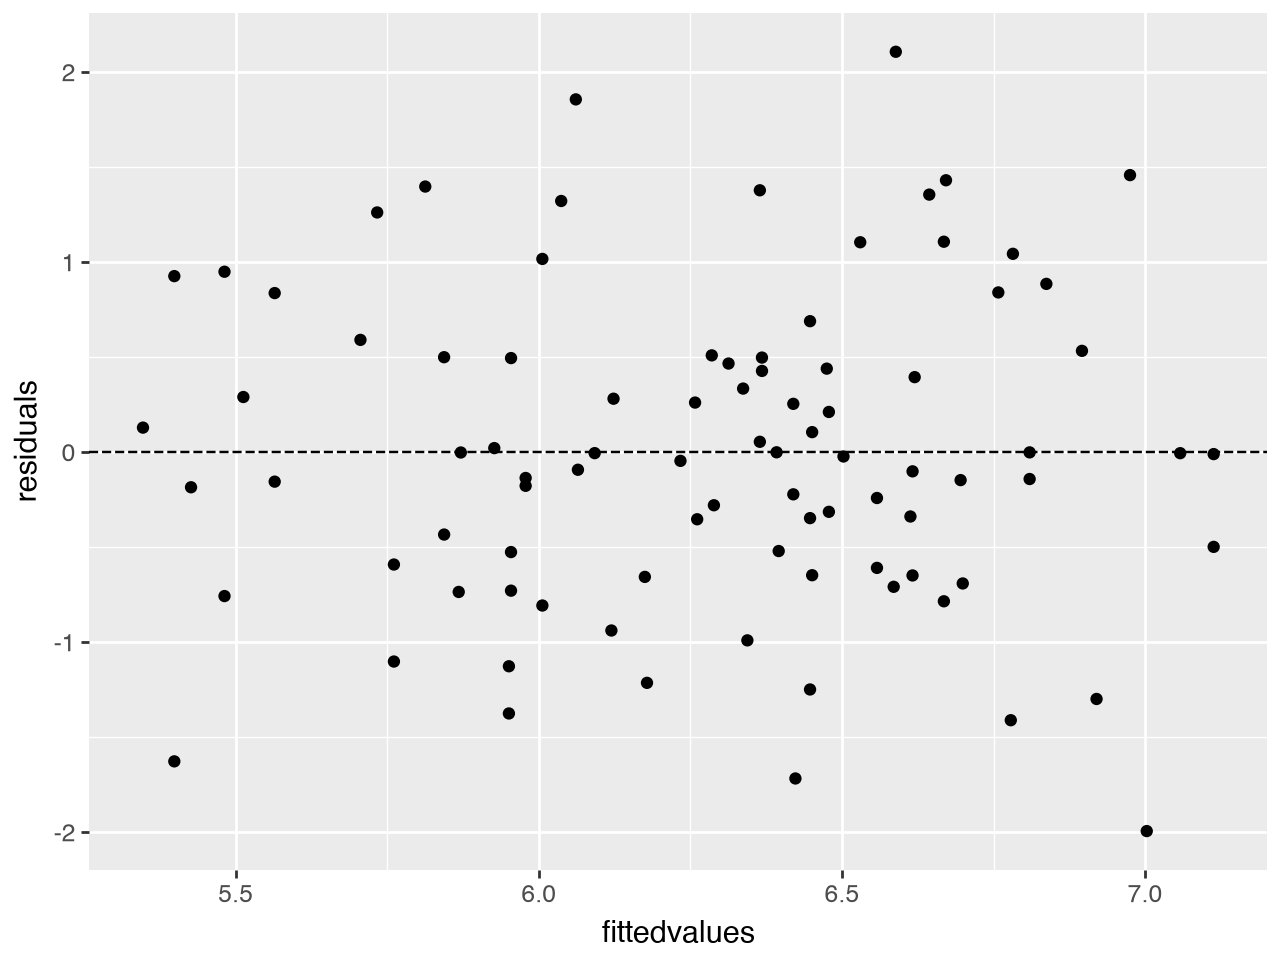

In [91]:
(ggplot(model_data_copy) +
    aes(x="fittedvalues", y="residuals") +
    geom_point() +
    geom_hline(yintercept=0, linetype="dashed")
)

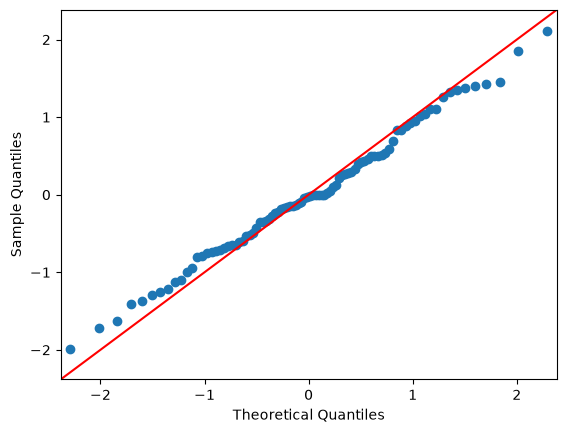

In [93]:
sm.qqplot(adjusted.resid, line='45')

In [100]:
summary_frame = adjusted.get_influence().summary_frame()

summary_frame.loc[summary_frame["cooks_d"] == summary_frame["cooks_d"].max()]

,dfb_Intercept,dfb_array_type[T.array_B],dfb_protocol[T.v2],dfb_age_centered,cooks_d,standard_resid,hat_diag,dffits_internal,student_resid,dffits
352,0.065314,-0.305544,0.121064,-0.379475,0.07136,-2.385373,0.047769,-0.534268,-2.454036,-0.549647


In [106]:
model_data

,patient_id,diag_mean_kohm,age_at_implant_years,array_type,protocol,age_centered
0,CI001,3.770924,29.0,array_A,v1,-21.0
4,CI002,6.807697,68.0,array_B,v1,18.0
7,CI003,5.966906,61.0,array_B,v1,11.0
15,CI005,6.008733,49.0,array_B,v2,-1.0
18,CI006,6.514826,73.0,array_A,v2,23.0
...,...,...,...,...,...,...
341,CI092,7.634036,70.0,array_A,v1,20.0
344,CI093,5.876097,72.0,array_A,v1,22.0
348,CI094,5.131561,46.0,array_A,v1,-4.0
352,CI095,5.007935,75.0,array_B,v1,25.0


It is Patient CI095

## Task 6 — A robust-standard-error sensitivity check (7 min)
Refit the **same adjusted formula and sample** with `.fit(cov_type="HC3")`, naming the result `robust`. Compare point estimates and confidence-interval widths with `adjusted`.

Acceptance: the coefficient estimates agree numerically; the interval widths may change. Use `np.allclose(...)`. Explain what HC3 addresses and what it does not: it changes covariance estimation for heteroskedasticity, not the fitted mean model, omitted-variable bias, or patient dependence.

Write whether your substantive interpretation changes. Do not choose a covariance estimator based on which gives a smaller p-value.

In [107]:
robust = smf.ols("diag_mean_kohm ~ age_centered + array_type + protocol", 
                   data=model_data,
                   missing='raise').fit(cov_type='HC3')

In [108]:
coef_table_robust = pd.DataFrame(robust.params).reset_index().rename(columns={"index": "parameter", 0: "value"})
conf_table_robust = robust.conf_int().reset_index().rename(columns={"index": "parameter", 0: "lower", 1: "upper"})

coef_table_robust = coef_table_robust.merge(
    conf_table_robust,
    on="parameter",
    how="left"
)
coef_table_robust


,parameter,value,lower,upper
0,Intercept,5.978167,5.685407,6.270926
1,array_type[T.array_B],0.334612,-0.036870,0.706095
2,protocol[T.v2],0.003533,-0.343608,0.350674
3,age_centered,0.027595,0.015352,0.039837


In [109]:
coef_table

,parameter,value,lower,upper
0,Intercept,5.978167,5.697266,6.259067
1,array_type[T.array_B],0.334612,-0.026757,0.695982
2,protocol[T.v2],0.003533,-0.445595,0.452660
3,age_centered,0.027595,0.015727,0.039462


## Task 7 — Plot adjusted mean predictions (8 min)
Build a small prediction DataFrame with ages from 30 through 75, both array categories, `protocol="v1"`, and correctly centered age. Use `robust.get_prediction(grid).summary_frame()` to obtain fitted means and confidence intervals.

With plotnine, draw a line and ribbon for each array. Show observed data if helpful but label the protocol held fixed. Use `mean`, `mean_ci_lower`, and `mean_ci_upper` from the prediction summary.

Unrelated grid construction:
```python
from itertools import product
new_data = pd.DataFrame(product([10, 20, 30], ["clay", "sand"]), columns=["rainfall", "soil"])
```
Hint: reset indexes before concatenating the grid and prediction summary. A mean confidence band is not an individual-patient prediction interval. Avoid extrapolating beyond the observed age support.

## Task 8 — A short results paragraph (5 min)
Write a five-sentence result: analysis sample and exclusions; one adjusted effect and 95% interval; a diagnostic observation; the HC3 sensitivity result; and a limitation involving observational comparison or measurement settings.

Conclude with a follow-up analysis you would prioritize and why. Do not interpret fictional array labels as actual product comparisons.

## Retrieval practice
Read this proposed shortcut: `smf.ols("diag_mean_kohm ~ months_since_implant", data=features).fit()`. Identify the repeated-observation problem and the measurement-setting variable it omits. Explain why simply having 360 rows does not give 360 independent people.

## Professional reasoning
1. Why does adjusting for measured covariates not prove that array type causes a difference?
2. What could go wrong if missing ages were associated with patient characteristics or outcomes?
3. Why would fitting 144 separate cellwise regressions require a plan for dependence and multiple comparisons?

## Self-check and reflection
Record confidence **1–5**, the hardest point, one operation you can now explain, what needs repetition, and whether the workload was too light / about right / too heavy.

Finish line: restart the kernel, run your cells in order, and write a short research conclusion with its limitations. Ask for review of your attempt.

## Optional extension — outside the core hour
**20 minutes:** Fit an age-by-array interaction on the same sample, plot its adjusted predictions, and compare the scientific question with the additive model. Treat this as exploratory. Separately refit after excluding the most influential observation, reporting both fits and a reason this is sensitivity analysis rather than permission to discard inconvenient data.

Reference: [statsmodels formula examples](https://www.statsmodels.org/stable/example_formulas.html).